# QEC Syndrome Visualizer -- Interactive Visualizer, Decoder, and Physical Timeline (aka The Q - Line)
## 2026 CU Boulder QISKIT Hackathon Submission
### Daniel Ritchie ([brainwavecoder9](https://github.com/brainwavecoder9)), Mullai Vaneshwar Sampangi Raman ([kuramaku88](https://github.com/kuramaku88)), Timothy Williams ([Manta4000](https://github.com/Manta4000)), Sean Flannery ([sflans99](https://github.com/sflans99))

## Hackathon Prompt
Our submission fits into Track-2 (Advanced) of the provided prompts. We chose to develop a QEC visualizer which accurately displays distance-3 surface code circuit syndrome decoding steps.

## Project Overview
The QEC Syndrome Visualizer is an interactive educational and demonstration platform for understanding how quantum error correction (QEC) works in a distance-3 rotated surface code. The project is designed to make the otherwise abstract behavior of syndrome extraction, detection events, and decoding visible and intuitive.

At the core of the system is a distance-3 rotated surface code with nine data qubits and eight syndrome-check qubits. The code repeatedly measures stabilizer checks, detects parity violations, and uses a MWPM decoder to infer a likely correction. The result is a live, step-by-step visual of how a data error propagates through the syndrome extraction rounds and how a decoder attempts to repair it.

Our goal is to bridge the gap between theory and intuition. While QEC is central to scalable fault-tolerant quantum computing, it is often difficult to understand from raw circuits alone. This tool turns the process into an interactive timeline: faults can be injected, syndrome rounds can be replayed, and the correction path can be observed in real time.

The project combines:

* a Qiskit-based simulation engine
* a symbolic and graphical representation of syndrome rounds
* a live LED-panel style visualization inspired by the physical device concept
* a decoder step that uses matching-based inference to propose corrections.

This makes the system useful both as a research aid and as a public-facing demo for explaining how a surface-code memory works.

## Background & References

Quantum error correction is necessary because real quantum hardware is noisy. Small physical errors can accumulate quickly, and without active correction, a logical qubit cannot remain reliable. Surface codes are among the most promising QEC architectures because they are planar, local, and compatible with physical hardware constraints.

This project draws on the standard distance-3 rotated surface-code layout, where stabilizers detect X and Z-type errors across small groups of neighboring data qubits. The key insight is that a local Pauli error produces a detectable syndrome pattern that can be decoded to identify the most likely correction.

### Relevant references and inspiration for this work include:

* CU Boulder Qiskit Hackathon prompt materials
* Fault-Tolerant Stabilizer Measurements in Surface Codes with Three-Qubit Gates
* NVIDIA QEC reference material
* Prior interactive quantum visualization projects and circuit animation examples that emphasized intuitive learning over raw numerical output

The central educational goal is to show that a syndrome pattern is not just a list of measurement outcomes it is a physical fingerprint of where errors occurred in spacetime. We use this idea to highlight how data errors, measurement faults, and the decoder interact.

## System Description

The system is built around a repeated syndrome-extraction cycle for a rotated surface code memory in the |0_L> state. The code models a d=3 surface-code memory with nine data qubits and uses four X checks and four Z checks to measure stabilizers and detect parity flips.

## Technical Implementation

### Core Simulation Model
The simulation engine uses Qiskit and Aer to run a stabilizer-based circuit one step at a time. Each round is structured as a repeated sequence:

1) X checks
2) Z checks
3) Decode + correct

This matches the canonical syndrome-extraction pattern used in surface-code memories. The implementation preserves the stabilizer state across steps so that errors introduced into the system persist and are visible throughout the cycle.

### Fault Injection
The project includes support for injecting Pauli faults on individual data qubits, such as X, Y, and Z errors. These faults can be applied in real time through the interactive UI, physical buttonts or replayed from a saved history. This allows us to demonstrate how different errors leave distinct syndrome patterns.

The interactive-visualizer only has depolarizing errors, but it would be rather straight forward to introduce errors of other classes including measurement errors. But one can still generate frames for any kind if errors and replay it on the display.

### Syndrome Extraction and Decoding

The system records the raw ancilla measurement outcomes for each stabilizer check, then computes detection events by comparing them with the expected reference values. In practice, detected syndromes are passed to a matching-based decoder, which infers the most likely error chain consistent with the observed parity flips.

In this project, the decoder is implemented using PyMatching. The correction is then applied to the internal simulated state, and the remaining residual error is tracked to determine whether a logical failure has occurred. This allows the demonstration to go beyond simply highlighting broken checks: it shows how QEC actively repairs the system and how some errors remain undetectable or uncorrectable at the logical level.

### Visualization and User Interface
The graphical front end, implemented in the live visualizer, turns these simulation steps into a board-like display:

* nine data qubits shown as D1 through D9
* four X checks and four Z checks displayed as stabilizer nodes
* colored state indicators for check outcomes
* correction highlighting over the data qubits
* a cycle-by-cycle log showing the syndrome and decoder result.

The interface supports:

* live simulation mode
* replay mode for saved runs
* injection of faults with selectable Pauli type
* stepping through cycles
* reset and replay controls
* and a save pipeline for exporting frames to be replayed or sent to an LED display

The project’s physical-device concept is reflected in the LED panel design: the board displays a simplified surface-code state using colored nodes and logical relationships between syndrome measurements and data qubits. This is especially useful for a live demonstration, where a visitor can press a qubit button, inject an error, and see its spacetime signature on the logical board.

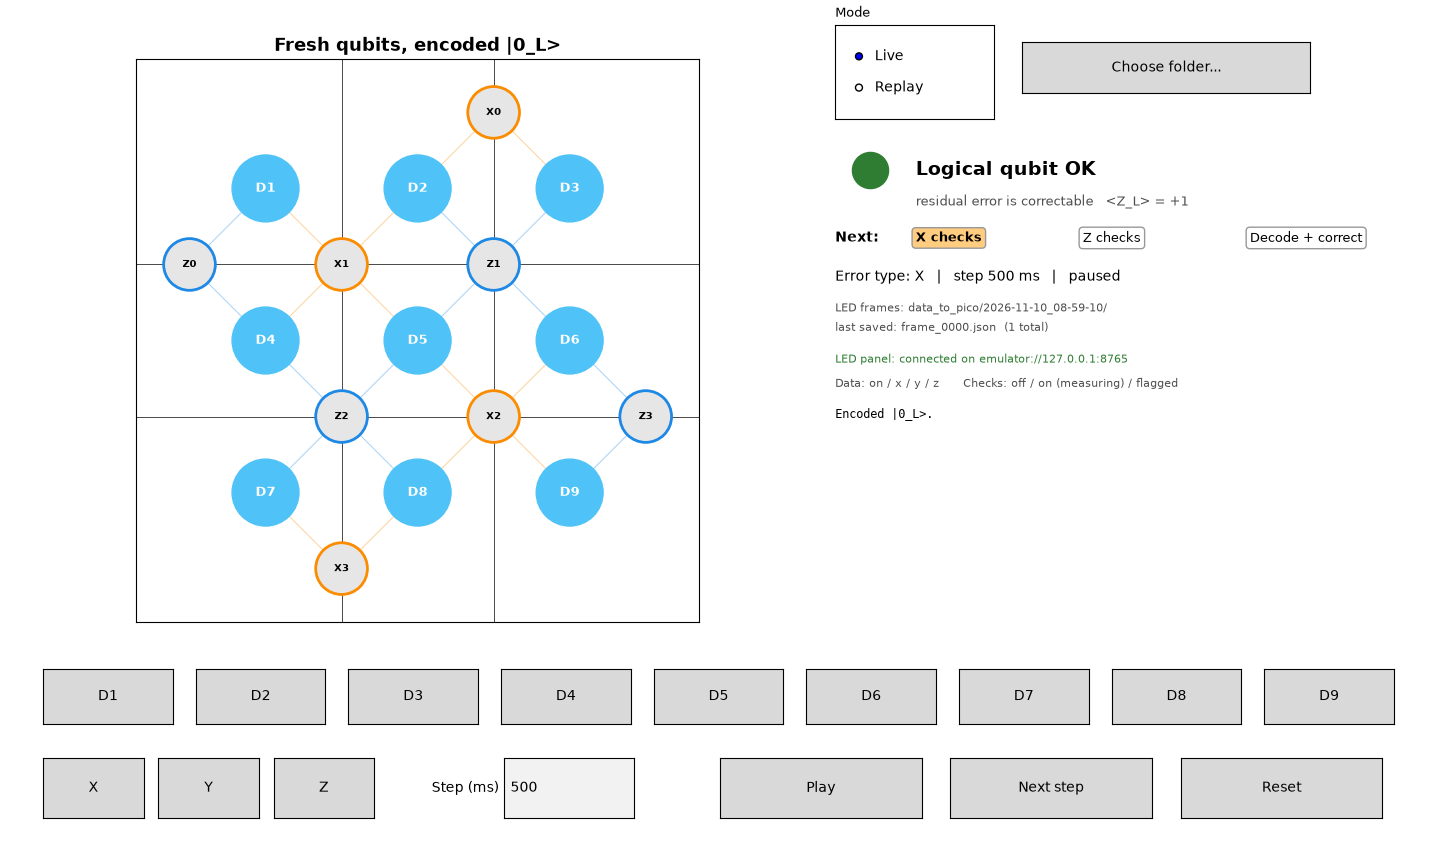
![Hardware Interface](attachment:display_integration.png)

## System Requirements

The codebase reflects a layered architecture that separates the simulation, visualization, and hardware-facing components.

# Simulation Logic
The simulation layer is built with qiskit around repeated stabilizer extraction and step recording. The core primitives include:

* construction of the rotated surface-code circuit
* check scheduling for X and Z syndrome extraction
* fault injection at specific points in the circuit
* sequence tracking of rounds and steps
* post-processing of measurement outcomes into syndrome and decode summaries

This layer is designed so that the state is preserved from one simulation step to the next, which is critical for demonstrating how the same error remains present until corrected.

### Visualization and Replay
The visualizer reads the output of the simulation and renders a board showing:

* syndrome check states
* data qubit states
* logical correction overlays
* the current decoder result

A replay mode also loads saved frame history and replays the event stream in order, enabling a deterministic demonstration of past runs. This is particularly useful for explaining to an audience how a specific injected fault produced a visible syndrome pattern and correction path. 

### Hardware Interface
The system is designed to support a physical LED-panel output. Frames are written to a data directory and can be sent to an external LED device through a linked interface. This allows the same underlying simulation to be expressed in a hardware-like display: the physical board becomes a surface-code memory “truth table” visible to an audience.

The intended hardware concept is aligned with the README: an acrylic board with labeled data qubits and stabilizer checks, a set of buttons for injecting errors, and a display that visualizes the syndrome extraction rounds over time. The software implementation is a simulation-first prototype for that physical experience.

## Discussion

Our technical submission is comprised of three major phases of product development.

1) Quantum circuit, IBM - Qiskit Interface & data collection and/or Qiskit-AER simulation
2) Digital visualization app for realtime error tracking, fault injection, and/or replay system
3) Firmware integration with physical LED-based display for 10-step QEC propogation and decoding step visualization

We explored multiple decoding methods for post QEC detection and identification, including Union-Find methods and Minimum-Weight Perfect Matching. We ultimately ended up using PyMatching library's MWPM method, given its consistency to flip ancilla bits compared to panqec's Union-Find decoder. We drew architectural inspiration from NVIDIA CUDA. 

## Concluding Statements

With the rising prelevance of QEC in the NISQ era, it becomes even more crucial for any QC enthusiast to understand the bheaviour of QEC models. With rotated surface codes being one of the most widely used codes right now, developing an intuitive understanding for such codes would help anyone attempting to get into the QC space. 

The QEC Syndrome Visualizer demonstrates how a surface-code memory behaves under realistic error conditions and how syndrome extraction and decoding operate in practice. It combines a mathematically faithful simulation engine with an intuitive visual interface and a physical-display concept to highlight the core ideas of fault-tolerant quantum computing.

It is an interactive, human-readable model of a working QEC memory: a system that can inject errors, measure syndromes, infer the likely correction, and evaluate whether the logical qubit survives. That combination of simulation, education, and physical visualization is the central contribution of the project.

We believe this tool has strong value as both a technical proof of concept and a demo-ready educational instrument for understanding the logic of fault-tolerant quantum computing.